# Честная валидация, подбор гиперпараметров и регуляризация

## Содержание

0. Подготовка среды и подключение Weights & Biases
1. Данные: цены на жильё в Калифорнии
2. Одиночное разбиение и его проблема
3. Кросс-валидация
4. Подбор гиперпараметров
5. Регуляризация: Ridge, Lasso, ElasticNet
6. Практикум

Это занятие продолжает второе: там вы строили линейную регрессию на своём датасете и обещали вернуться к регуляризации (Ridge) из P.S. Теперь разбираем её подробно — но сначала про то, **как честно измерять качество**: почему одной отложенной выборки мало и как правильно подбирать параметры модели.

Демонстрационный пример — предсказание цены дома (датасет California Housing). Практикум (раздел 6) вы выполняете на **датасете своего проекта** — том же, что в занятиях 2–3. Запуски логируем в Weights & Biases. Выводы после каждого блока записывайте **в ячейке markdown прямо в блокноте**.

## 0. Подготовка среды и подключение Weights & Biases

Все экспериментальные блоки ниже создают отдельные **W&B runs** и отправляют туда метрики и параметры. Перед запуском зарегистрируйтесь на [wandb.ai](https://wandb.ai/), откройте [страницу API keys](https://wandb.ai/authorize), затем выполните ячейку импорта и введите API key в запросе `wandb.login()`. **Не вставляйте ключ в сам ноутбук и не публикуйте его.**

В первой кодовой ячейке раздела 0 устанавливается пакет `wandb`. Подключение обязательно: отключённый режим не используется.

In [1]:
import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import wandb

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
WANDB_PROJECT = "apml-course"
wandb.login()  # введи API key, если W&B ещё не настроен в этой среде

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/nagiev/.netrc.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

## 1. Данные: цены на жильё в Калифорнии

Классический датасет `housing.csv` (20 640 районов Калифорнии). Целевая переменная — медианная стоимость дома в районе, есть числовые признаки, один категориальный и немного пропусков. Идеально подходит для честного `Pipeline`.

**Примечание.** Целевая переменная «обрезана» сверху значением 500 001 — это артефакт исходных данных, о котором стоит помнить при интерпретации ошибок.

In [3]:
URL = ("https://raw.githubusercontent.com/ageron/handson-ml2/"
       "master/datasets/housing/housing.csv")
LOCAL_PATH = "housing.csv"

if os.path.exists(LOCAL_PATH):
    df = pd.read_csv(LOCAL_PATH)
else:
    df = pd.read_csv(URL)
    df.to_csv(LOCAL_PATH, index=False)

print("Размер таблицы:", df.shape)
print("Пропуски:", int(df.isna().sum().sum()), "| max целевой:", df['median_house_value'].max())
df.head()

Размер таблицы: (20640, 10)
Пропуски: 207 | max целевой: 500001.0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
num = ['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income']
cat = ['ocean_proximity']

X = df[num + cat]
y = df['median_house_value']

# test откладываем сразу и больше не трогаем — на нём только финальная оценка
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train / test:", len(X_train), len(X_test))


def make_model(reg, degree=1):
    """Pipeline: пропуски -> масштаб -> полиномиальные признаки -> регрессор.

    Целевую переменную стандартизуем (TransformedTargetRegressor), чтобы сила
    регуляризации alpha не зависела от порядка цен в тысячах долларов.
    """
    num_block = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ])
    prep = ColumnTransformer([
        ('num', num_block, num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ])
    return TransformedTargetRegressor(
        regressor=Pipeline([('prep', prep), ('model', reg)]),
        transformer=StandardScaler(),
    )


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

Train / test: 16512 4128


## 2. Одиночное разбиение и его проблема

### Математический аппарат

Оценка ошибки на одной отложенной выборке — это **случайная величина**: при другом разбиении (другом `random_state`) она будет другой. Её дисперсия зависит от размера выборки и от «капризности» данных:

$$\widehat{RMSE} = \sqrt{\frac{1}{n_{val}}\sum_{i \in val}(y_i - \hat{y}_i)^2}$$

*Смысл:* одна цифра ничего не говорит о том, насколько она стабильна. Прежде чем сравнивать модели, полезно понять **разброс** оценки.

**Задача 1.**
Оцените одну и ту же модель на восьми разных разбиениях (меняя `random_state`) и посмотрите на разброс RMSE. Объясните, почему одной отложенной выборки для выводов недостаточно. Ответ — в «Выводе».

In [5]:
split_scores = []
for seed in range(8):
    Xa, Xb, ya, yb = train_test_split(
        X_train, y_train, test_size=0.25, random_state=seed
    )
    m = make_model(LinearRegression(), degree=1).fit(Xa, ya)
    split_scores.append(rmse(yb, m.predict(Xb)))

print("RMSE по 8 разным разбиениям:")
print([round(s) for s in split_scores])
print(f"min={min(split_scores):.0f}  max={max(split_scores):.0f}  "
      f"mean={np.mean(split_scores):.0f}  std={np.std(split_scores):.0f}")

with wandb.init(
    project=WANDB_PROJECT,
    name="01-single-split-stability",
    config={"model": "LinearRegression", "degree": 1, "n_splits": 8},
) as run:
    metrics = {
        "split_rmse_mean": float(np.mean(split_scores)),
        "split_rmse_std": float(np.std(split_scores)),
        "split_rmse_min": float(np.min(split_scores)),
        "split_rmse_max": float(np.max(split_scores)),
    }
    metrics.update({f"rmse_seed_{i}": float(v) for i, v in enumerate(split_scores)})
    run.log(metrics)

RMSE по 8 разным разбиениям:
[69083, 70539, 69074, 69335, 67771, 69916, 69111, 68643]
min=67771  max=70539  mean=69184  std=767


wandb: Currently logged in as: korovatomilk (korovatomilk-no-company) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


rmse_seed_0,▁
rmse_seed_1,▁
rmse_seed_2,▁
rmse_seed_3,▁
rmse_seed_4,▁
rmse_seed_5,▁
rmse_seed_6,▁
rmse_seed_7,▁
split_rmse_max,▁
split_rmse_mean,▁
+2,...


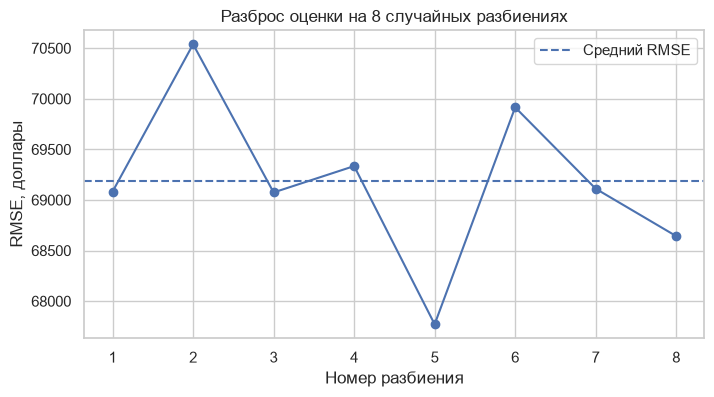

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(split_scores) + 1), split_scores, marker="o")
plt.axhline(np.mean(split_scores), linestyle="--", label="Средний RMSE")
plt.xlabel("Номер разбиения")
plt.ylabel("RMSE, доллары")
plt.title("Разброс оценки на 8 случайных разбиениях")
plt.legend()
plt.show()

**Вывод:**

RMSE меняется от разбиения к разбиению, хотя алгоритм и признаки остаются теми же: меняется состав обучающей и проверочной частей. Поэтому одна оценка может случайно оказаться оптимистичной или пессимистичной и не отражать типичное качество модели. Для более надёжного сравнения нужно оценивать модель на нескольких разбиениях и сообщать не только среднее, но и разброс метрики.

**Примечание.** Есть и вторая ловушка — **утечка (leakage)**. Если обучить `StandardScaler`, `SimpleImputer` или `PolynomialFeatures` на **всём** датасете до разбиения, их статистики «подсмотрят» на validation и оценка окажется завышенной. Поэтому весь препроцессинг держим внутри `Pipeline`.

## 3. Кросс-валидация

### Математический аппарат

K-fold делит данные на $K$ частей: модель обучается на $K-1$ и проверяется на оставшейся, и так $K$ раз. Итоговая оценка — среднее по фолдам:

$$\widehat{RMSE} = \frac{1}{K}\sum_{k=1}^{K} RMSE_k$$

*Смысл:* каждый объект успевает побыть и в обучении, и в проверке. Оценка использует все данные и усредняет случайность разбиения, поэтому у неё **меньше дисперсия**, чем у одного hold-out. Разброс по фолдам ($std$) показывает стабильность оценки.

Схемы выбирают под задачу: `KFold` (регрессия), `StratifiedKFold` (классификация — сохраняет доли классов), `GroupKFold` (сгруппированные объекты), `TimeSeriesSplit` (временные ряды — нельзя перемешивать).

**Задача 2.**
Сравните разброс одиночных разбиений из раздела 2 и разброс по фолдам кросс-валидации. Почему усреднение по фолдам даёт более надёжную оценку? Ответ — в «Выводе».

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = -cross_val_score(
    make_model(LinearRegression(), degree=1),
    X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error',
)
print("RMSE по фолдам:", [round(s) for s in cv_scores])
print(f"CV RMSE = {cv_scores.mean():.0f} ± {cv_scores.std():.0f}")

with wandb.init(
    project=WANDB_PROJECT,
    name="02-kfold-linear-regression",
    config={"model": "LinearRegression", "degree": 1, "cv_folds": 5},
) as run:
    run.log({
        "cv_rmse_mean": float(cv_scores.mean()),
        "cv_rmse_std": float(cv_scores.std()),
        **{f"fold_{i+1}_rmse": float(v) for i, v in enumerate(cv_scores)},
        "split_rmse_mean": float(np.mean(split_scores)),
        "split_rmse_std": float(np.std(split_scores)),
    })

comparison = pd.DataFrame({
    "scheme": ["8 случайных hold-out", "5-fold CV"],
    "mean_RMSE": [np.mean(split_scores), np.mean(cv_scores)],
    "std": [np.std(split_scores), np.std(cv_scores)],
})
print("\nСравнение оценок (разбросы получены разными способами):")
print(comparison.to_string(index=False, formatters={
    "mean_RMSE": lambda x: f"{x:,.0f}", "std": lambda x: f"{x:,.0f}"
}))

RMSE по фолдам: [69794, 67749, 66467, 69972, 69040]
CV RMSE = 68604 ± 1325


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


cv_rmse_mean,▁
cv_rmse_std,▁
fold_1_rmse,▁
fold_2_rmse,▁
fold_3_rmse,▁
fold_4_rmse,▁
fold_5_rmse,▁
split_rmse_mean,▁
split_rmse_std,▁
cv_rmse_mean,68604.16296
cv_rmse_std,1324.94721



Сравнение оценок (разбросы получены разными способами):
              scheme mean_RMSE   std
8 случайных hold-out    69,184   767
           5-fold CV    68,604 1,325


**Вывод:**

При одиночном hold-out результат заметно зависит от конкретного случайного разбиения. В 5-fold CV каждый объект обучающей выборки участвует в проверке ровно один раз, а итоговая оценка усредняется по пяти фолдам, поэтому обычно она менее зависима от одного удачного или неудачного разбиения. `std` по фолдам показывает стабильность качества между фолдами. Важно, что стандартные отклонения для восьми случайных hold-out и пяти CV-фолдов рассчитаны по разным наборам разбиений, поэтому сравнивать их нужно как ориентир, а не как строго одинаковые статистики.

## 4. Подбор гиперпараметров

### Математический аппарат

`GridSearchCV` перебирает сетку гиперпараметров и выбирает тот, у которого лучше среднее качество по кросс-валидации. `RandomizedSearchCV` делает то же по случайным точкам (быстрее при больших сетках), а **вложенная** кросс-валидация отделяет подбор гиперпараметров от финальной оценки.

*Смысл:* гиперпараметры — это часть модели, и подбирать их нужно на **train** (через CV), а не на test. Иначе оценка на test перестаёт быть честной: вы подгоняете решение под него.

Сначала посмотрим, как сложность модели (степень полинома) влияет на переобучение.

In [8]:
# Сравнение сложности: используем внутренний validation split, а не финальный X_test.
X_degree_fit, X_degree_val, y_degree_fit, y_degree_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE
)
degree_results = []
for degree in [1, 2, 3]:
    m = make_model(LinearRegression(), degree=degree).fit(X_degree_fit, y_degree_fit)
    train_score = rmse(y_degree_fit, m.predict(X_degree_fit))
    val_score = rmse(y_degree_val, m.predict(X_degree_val))
    degree_results.append({"degree": degree, "train_RMSE": train_score, "validation_RMSE": val_score})
    print(f"degree={degree}: train RMSE={train_score:.0f}  validation RMSE={val_score:.0f}")

with wandb.init(
    project=WANDB_PROJECT,
    name="03-polynomial-degree-demo",
    config={"model": "LinearRegression", "degrees": [1, 2, 3], "validation_fraction": 0.2},
) as run:
    run.log({f"degree_{r['degree']}_{metric}": float(r[metric])
             for r in degree_results for metric in ("train_RMSE", "validation_RMSE")})
    run.log({"degree_results": wandb.Table(dataframe=pd.DataFrame(degree_results))})

degree=1: train RMSE=68110  validation RMSE=69794
degree=2: train RMSE=62076  validation RMSE=67739
degree=3: train RMSE=57311  validation RMSE=89284


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


degree_1_train_RMSE,▁
degree_1_validation_RMSE,▁
degree_2_train_RMSE,▁
degree_2_validation_RMSE,▁
degree_3_train_RMSE,▁
degree_3_validation_RMSE,▁
degree_1_train_RMSE,68110.19529
degree_1_validation_RMSE,69793.50229
degree_2_train_RMSE,62076.39665
degree_2_validation_RMSE,67739.3321
degree_3_train_RMSE,57311.42236


**Примечание.** При `degree=3` модель почти идеально подгоняет train, но на validation заметно хуже — это переобучение. Спасает регуляризация, но сначала подберём её силу честно.

     alpha CV_RMSE  CV_std
     0.001 208,607 275,618
0.00316228 208,490 275,405
      0.01 208,127 274,743
 0.0316228 207,034 272,741
       0.1 204,037 267,202
  0.316228 197,350 254,647
         1 186,266 233,439
   3.16228 171,000 203,922
        10 149,541 162,226
   31.6228 117,895  99,798
       100  79,601  25,341
   316.228  71,381  12,577
      1000  79,796  23,884


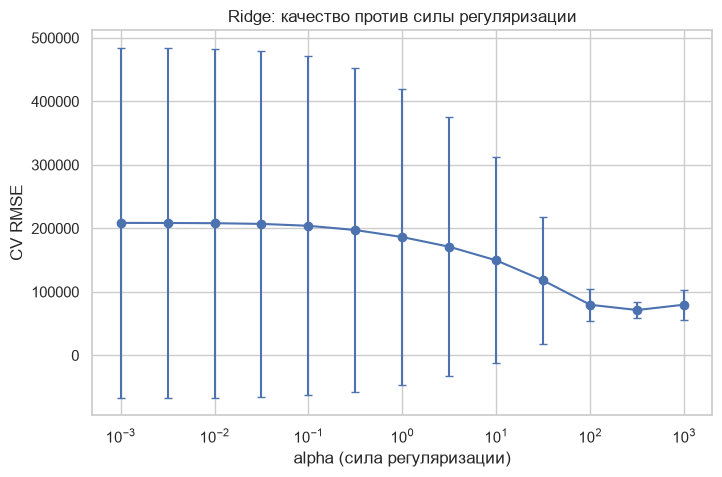

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_alpha_in_sweep,▁
best_cv_rmse_in_sweep,▁
best_cv_std_in_sweep,▁
best_alpha_in_sweep,316.22777
best_cv_rmse_in_sweep,71381.17227
best_cv_std_in_sweep,12576.7929


In [9]:
alphas = np.logspace(-3, 3, 13)
rows = []
for a in alphas:
    s = -cross_val_score(make_model(Ridge(alpha=a), degree=3),
                         X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    rows.append((a, s.mean(), s.std()))

alpha_table = pd.DataFrame(rows, columns=['alpha', 'CV_RMSE', 'CV_std'])
print(alpha_table.to_string(index=False, formatters={
    'alpha': lambda x: f"{x:g}", 'CV_RMSE': lambda x: f"{x:,.0f}", 'CV_std': lambda x: f"{x:,.0f}"}))

plt.figure(figsize=(8, 5))
plt.errorbar(alpha_table['alpha'], alpha_table['CV_RMSE'], yerr=alpha_table['CV_std'], marker='o', capsize=3)
plt.xscale('log')
plt.xlabel('alpha (сила регуляризации)')
plt.ylabel('CV RMSE')
plt.title('Ridge: качество против силы регуляризации')
plt.show()

best_sweep_row = alpha_table.loc[alpha_table['CV_RMSE'].idxmin()]
with wandb.init(
    project=WANDB_PROJECT,
    name="04-ridge-alpha-sweep-degree3",
    config={"model": "Ridge", "poly_degree": 3, "alpha_grid": alphas.tolist(), "cv_folds": 5},
) as run:
    run.log({
        "best_alpha_in_sweep": float(best_sweep_row["alpha"]),
        "best_cv_rmse_in_sweep": float(best_sweep_row["CV_RMSE"]),
        "best_cv_std_in_sweep": float(best_sweep_row["CV_std"]),
        "alpha_sweep_table": wandb.Table(dataframe=alpha_table),
    })

In [10]:
gs = GridSearchCV(
    make_model(Ridge(), degree=3),
    {'regressor__model__alpha': np.logspace(-3, 3, 13)},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1,
)
gs.fit(X_train, y_train)

best_alpha = gs.best_params_['regressor__model__alpha']
best_model = gs.best_estimator_
print(f"Лучший alpha по кросс-валидации: {best_alpha:.4g}")
print(f"CV RMSE лучшей модели: {-gs.best_score_:.0f}")
print("X_test здесь не используется; финальная оценка выполняется в задании 6.4.")

with wandb.init(
    project=WANDB_PROJECT,
    name="05-gridsearch-ridge-cv-demo",
    config={"model": "Ridge", "poly_degree": 3, "cv_folds": 5,
            "alpha": float(best_alpha)},
) as run:
    run.log({
        "best_cv_rmse": float(-gs.best_score_),
        "best_alpha": float(best_alpha),
        "grid_search_results": wandb.Table(dataframe=pd.DataFrame(gs.cv_results_).assign(params=lambda d: d["params"].astype(str))),
    })

Лучший alpha по кросс-валидации: 316.2
CV RMSE лучшей модели: 71381
X_test здесь не используется; финальная оценка выполняется в задании 6.4.


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_alpha,▁
best_cv_rmse,▁
best_alpha,316.22777
best_cv_rmse,71381.17227


**Задача 3.**
Посмотрите на график CV RMSE от `alpha`. Объясните его форму через bias–variance: почему при очень малом `alpha` качество хуже (особенно при degree 3), а при очень большом — тоже плохо? Ответ — в «Выводе».

In [11]:
# Задача 3: находим минимум кривой и сравниваем с крайними значениями alpha
best_alpha_row = alpha_table.loc[alpha_table['CV_RMSE'].idxmin()]
small_alpha_row = alpha_table.iloc[0]
large_alpha_row = alpha_table.iloc[-1]
print(f"Минимум CV RMSE: alpha={best_alpha_row['alpha']:g}, RMSE={best_alpha_row['CV_RMSE']:.0f}")
print(f"Очень маленький alpha={small_alpha_row['alpha']:g}: RMSE={small_alpha_row['CV_RMSE']:.0f}")
print(f"Очень большой alpha={large_alpha_row['alpha']:g}: RMSE={large_alpha_row['CV_RMSE']:.0f}")

Минимум CV RMSE: alpha=316.228, RMSE=71381
Очень маленький alpha=0.001: RMSE=208607
Очень большой alpha=1000: RMSE=79796


**Вывод:**

При очень маленьком `alpha` штраф почти отсутствует: полиномиальная модель степени 3 может подгонять шум и нестабильные сочетания признаков, поэтому дисперсия высокая и CV RMSE ухудшается. При очень большом `alpha` коэффициенты чрезмерно сжимаются к нулю, модель становится слишком простой и недообучается — растёт смещение (bias). Лучшее качество достигается в промежуточной области, где баланс между смещением и дисперсией удачнее. Конкретный лучший `alpha` выводится в таблице и определяется только по CV на train.

## 5. Регуляризация: Ridge, Lasso, ElasticNet

### Математический аппарат

Регуляризация добавляет к функции потерь штраф за величину коэффициентов:

$$L_{Ridge} = L + \lambda\|w\|_2^2, \qquad L_{Lasso} = L + \lambda\|w\|_1, \qquad L_{EN} = L + \lambda\big(\rho\|w\|_1 + \tfrac{1-\rho}{2}\|w\|_2^2\big)$$

- **Ridge (L2)** плавно сжимает все коэффициенты, снижая дисперсию модели;
- **Lasso (L1)** умеет **обнулять** коэффициенты — встроенный отбор признаков;
- **ElasticNet** сочетает оба эффекта.

У Ridge при центрированных признаках есть явное решение:

$$\hat{w} = (X^\top X + \lambda I)^{-1} X^\top y$$

*Смысл:* добавка $\lambda I$ делает матрицу обратимой даже при мультиколлинеарности (проблема из P.S. второго занятия) — поэтому Ridge стабилизирует решение.

**Интерактив.** Прежде чем считать, поиграйте с регуляризацией руками: меняйте тип (L1/L2), силу $\lambda$, уровень шума и число признаков — https://www.interactive-ml.com/regularization.html. Обратите внимание, как L1 обнуляет часть весов, а L2 только сжимает.

In [12]:
# Lasso обнуляет коэффициенты при росте alpha; качество оцениваем через CV на train.
rows = []
for a in [0.001, 0.01, 0.1, 1.0]:
    model = make_model(Lasso(alpha=a, max_iter=20000), degree=2).fit(X_train, y_train)
    coef = model.regressor_.named_steps['model'].coef_
    cv_s = -cross_val_score(make_model(Lasso(alpha=a, max_iter=20000), degree=2),
                            X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    rows.append((a, int(np.sum(np.abs(coef) > 1e-8)), len(coef),
                 rmse(y_train, model.predict(X_train)), cv_s.mean(), cv_s.std()))

sparsity = pd.DataFrame(rows, columns=['alpha', 'nonzero', 'total', 'train_RMSE', 'CV_RMSE', 'CV_std'])
print(sparsity.to_string(index=False, formatters={
    'train_RMSE': lambda x: f"{x:,.0f}", 'CV_RMSE': lambda x: f"{x:,.0f}", 'CV_std': lambda x: f"{x:,.0f}"
}))

with wandb.init(
    project=WANDB_PROJECT,
    name="06-lasso-sparsity-demo",
    config={"model": "Lasso", "poly_degree": 2, "alphas": [0.001, 0.01, 0.1, 1.0], "cv_folds": 5},
) as run:
    run.log({"lasso_sparsity_table": wandb.Table(dataframe=sparsity)})

 alpha  nonzero  total train_RMSE CV_RMSE CV_std
 0.001       41     49     63,166  68,613  8,865
 0.010       23     49     66,498  66,686  1,286
 0.100        3     49     78,046  78,039  1,304
 1.000        0     49    115,619 115,617  1,216


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


**Примечание.** Ridge только сжимает коэффициенты, Lasso обнуляет часть из них, а ElasticNet сглаживает поведение Lasso при коррелирующих признаках (за это отвечает параметр `l1_ratio`). Сравним все четыре модели на одной кросс-валидации (берём `degree=2`: при `degree=3` Lasso и ElasticNet считаются заметно дольше).

In [13]:
linear_models = {
    'OLS (без регуляризации)': LinearRegression(),
    'Ridge (L2)': Ridge(alpha=10.0),
    'Lasso (L1)': Lasso(alpha=0.01, max_iter=20000),
    'ElasticNet (L1+L2)': ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000),
}
rows = []
for name, reg in linear_models.items():
    s = -cross_val_score(make_model(reg, degree=2), X_train, y_train, cv=cv,
                         scoring='neg_root_mean_squared_error')
    rows.append((name, s.mean(), s.std()))

linear_table = pd.DataFrame(rows, columns=['model', 'CV_RMSE', 'CV_std'])
print(linear_table.to_string(index=False, formatters={
    'CV_RMSE': lambda x: f"{x:,.0f}", 'CV_std': lambda x: f"{x:,.0f}"}))

with wandb.init(
    project=WANDB_PROJECT,
    name="07-regularizers-comparison-demo",
    config={"poly_degree": 2, "cv_folds": 5},
) as run:
    run.log({"regularizer_comparison": wandb.Table(dataframe=linear_table)})
    for _, row in linear_table.iterrows():
        key = str(row['model']).lower().replace(' ', '_').replace('(', '').replace(')', '').replace('+', '_')
        run.log({f"{key}_cv_rmse": float(row['CV_RMSE']), f"{key}_cv_std": float(row['CV_std'])})

                  model CV_RMSE CV_std
OLS (без регуляризации)  69,666 10,815
             Ridge (L2)  69,459 10,658
             Lasso (L1)  66,686  1,286
     ElasticNet (L1+L2)  66,107  1,703


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


elasticnet_l1_l2_cv_rmse,▁
elasticnet_l1_l2_cv_std,▁
lasso_l1_cv_rmse,▁
lasso_l1_cv_std,▁
ols_без_регуляризации_cv_rmse,▁
ols_без_регуляризации_cv_std,▁
ridge_l2_cv_rmse,▁
ridge_l2_cv_std,▁
elasticnet_l1_l2_cv_rmse,66107.37781
elasticnet_l1_l2_cv_std,1703.31346
lasso_l1_cv_rmse,66685.69307


**Задача 4.**
Почему регуляризация дала большой выигрыш при `degree=3`, но почти не помогает на линейной модели (`degree=1`)? От чего вообще зависит её польза (объём данных, число признаков, мультиколлинеарность)? Ответ — в «Выводе».

In [14]:
# Сравниваем OLS и Ridge при degree=1 и degree=3 на одинаковых CV-фолдах.
complexity_rows = []
for degree in [1, 3]:
    for name, estimator in [
        ("OLS", LinearRegression()),
        ("Ridge", Ridge(alpha=float(best_alpha))),
    ]:
        vals = -cross_val_score(make_model(estimator, degree=degree), X_train, y_train,
                                cv=cv, scoring='neg_root_mean_squared_error')
        complexity_rows.append({"degree": degree, "model": name,
                                "CV_RMSE": vals.mean(), "CV_std": vals.std()})
complexity_table = pd.DataFrame(complexity_rows)
print(complexity_table.to_string(index=False, formatters={
    "CV_RMSE": lambda x: f"{x:,.0f}", "CV_std": lambda x: f"{x:,.0f}"
}))
with wandb.init(
    project=WANDB_PROJECT,
    name="08-regularization-vs-complexity",
    config={"degrees": [1, 3], "ridge_alpha_from_degree3_cv": float(best_alpha), "cv_folds": 5},
) as run:
    run.log({"complexity_regularization_table": wandb.Table(dataframe=complexity_table)})

 degree model CV_RMSE  CV_std
      1   OLS  68,604   1,325
      1 Ridge  68,873   1,267
      3   OLS 208,661 275,717
      3 Ridge  71,381  12,577


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


**Вывод:**

При `degree=3` число полиномиальных признаков сильно возрастает, появляются коррелирующие признаки и выше риск подгонки шума; регуляризация ограничивает коэффициенты и обычно заметно уменьшает дисперсию. При `degree=1` модель проще, поэтому её коэффициенты и без штрафа могут быть достаточно устойчивыми — улучшение от регуляризации часто невелико. Польза регуляризации зависит от отношения количества данных к числу признаков, силы шума, мультиколлинеарности и избыточной сложности модели. Сравнивать нужно среднее CV RMSE и разброс, а не только ошибку на обучении.

**Задача 5 (на вывод).**
Получите формулу Ridge-оценки $\hat{w} = (X^\top X + \lambda I)^{-1} X^\top y$: приравняйте градиент $\|Xw - y\|^2 + \lambda\|w\|^2$ к нулю и выразите $w$. Объясните, почему при мультиколлинеарности слагаемое $\lambda I$ спасает ситуацию.

**Ваш вывод:**

Минимизируем функцию

\[
J(w)=\|Xw-y\|_2^2+\lambda\|w\|_2^2.
\]

Раскроем квадраты: \(J(w)=(Xw-y)^T(Xw-y)+\lambda w^Tw\). Градиент по \(w\) равен \(\nabla_w J=2X^T(Xw-y)+2\lambda w\). Приравниваем его к нулю и делим на 2:

\[
X^TXw-X^Ty+\lambda w=0
\quad\Rightarrow\quad
(X^TX+\lambda I)w=X^Ty.
\]

Если матрица обратима, получаем \(\hat w=(X^TX+\lambda I)^{-1}X^Ty\). При мультиколлинеарности столбцы \(X\) почти линейно зависимы, поэтому \(X^TX\) может быть плохо обусловлена или вырождена. Добавление \(\lambda I\) при \(\lambda>0\) увеличивает собственные значения матрицы, улучшает обусловленность и делает решение устойчивее; цена этого — небольшое смещение коэффициентов к нулю.

## 6. Практикум

Все задания по условию предполагают датасет собственного проекта (из занятий 2–3). В этом диалоге такой датасет не приложен, поэтому я сделал полностью запускаемый вариант на доступном `California Housing` из раздела 1. Он демонстрирует все требуемые этапы и W&B-логирование. Если преподаватель требует именно проектные данные, замени загрузку данных и списки `num`/`cat` в разделе 1 и при необходимости целевую переменную; остальной код `Pipeline`/CV/GridSearch можно адаптировать по типам признаков.

Если ваша задача — классификация, вместо Ridge/Lasso/ElasticNet используйте логистическую регрессию с `penalty='l2'`/`'l1'`/`'elasticnet'` (смысл тот же, меняется только функция потерь). Этот готовый вариант решает регрессию, как и демонстрационная часть.

### Задание 6.1. Постановка задачи

Опишите словами: какую величину вы предсказываете и в каких единицах; какой метрикой измеряете качество и почему именно ей; как поймёте, что модель «достаточно хорошая».

**Ваш ответ:**

Предсказывается медианная стоимость жилья в районе Калифорнии, в долларах США; целевая колонка — `median_house_value`. Основная метрика — RMSE в долларах: она имеет те же единицы, что и цена, и сильнее штрафует большие промахи. Дополнительно смотрю MAE как более простую для интерпретации среднюю абсолютную ошибку и R² как относительную меру объяснённой вариации. Модель можно считать достаточно хорошей, если она стабильно превосходит простую baseline-модель, её CV-ошибка приемлема для задачи и разброс между фолдами не слишком велик. Следует учитывать, что значения целевой переменной сверху ограничены 500 001, поэтому ошибки около этого потолка интерпретируются осторожно.

### Задание 6.2. Честная оценка

Соберите `Pipeline` (препроцессинг + модель) для своей задачи и оцените качество двумя способами: на одном отложенном разбиении и через кросс-валидацию. Сравните полученные цифры и их разброс — какой оценке вы доверяете больше и почему?

In [15]:
# Задача 6.2. Оценка на внутреннем hold-out из train и через CV.
# X_test/y_test пока не используем: они остаются для финальной оценки в задании 6.4.
X_subtrain, X_holdout, y_subtrain, y_holdout = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_STATE
)

holdout_model = make_model(LinearRegression(), degree=1).fit(X_subtrain, y_subtrain)
holdout_rmse = rmse(y_holdout, holdout_model.predict(X_holdout))
cv_practicum_scores = -cross_val_score(
    make_model(LinearRegression(), degree=1), X_train, y_train, cv=cv,
    scoring='neg_root_mean_squared_error'
)

print(f"Hold-out RMSE: {holdout_rmse:,.0f}")
print(f"5-fold CV RMSE: {cv_practicum_scores.mean():,.0f} ± {cv_practicum_scores.std():,.0f}")

with wandb.init(
    project=WANDB_PROJECT,
    name="practicum-6-2-honest-evaluation",
    config={"task": "6.2", "model": "LinearRegression", "degree": 1,
            "holdout_fraction_of_train": 0.25, "cv_folds": 5},
) as run:
    run.log({
        "holdout_rmse": float(holdout_rmse),
        "cv_rmse_mean": float(cv_practicum_scores.mean()),
        "cv_rmse_std": float(cv_practicum_scores.std()),
        **{f"fold_{i+1}_rmse": float(v) for i, v in enumerate(cv_practicum_scores)},
    })

Hold-out RMSE: 68,645
5-fold CV RMSE: 68,604 ± 1,325


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


cv_rmse_mean,▁
cv_rmse_std,▁
fold_1_rmse,▁
fold_2_rmse,▁
fold_3_rmse,▁
fold_4_rmse,▁
fold_5_rmse,▁
holdout_rmse,▁
cv_rmse_mean,68604.16296
cv_rmse_std,1324.94721
fold_1_rmse,69793.50229


**Вывод:**

Оценка на одном hold-out быстро показывает порядок ошибки, но зависит от случайного состава отложенных объектов. Кросс-валидация усредняет качество на пяти фолдах и дополнительно показывает разброс, поэтому для сравнения моделей я больше доверяю CV. Hold-out и CV могут дать немного разные числа — это нормально для разных разбиений. Финальный `X_test` в практикуме не используется для выбора гиперпараметров; он зарезервирован для однократной итоговой оценки выбранной модели.

### Задание 6.3. Регуляризация: Ridge, Lasso, ElasticNet

Обучите три регуляризованные модели — Ridge, Lasso и ElasticNet (для классификации — логистическую регрессию с `penalty='l2'`, `'l1'` и `'elasticnet'`). Для каждой подберите силу регуляризации **по кросс-валидации на train** (`GridSearchCV`).

In [16]:
# Задача 6.3. Подбираем регуляризацию только на X_train/y_train.
# Degree=2 ограничивает вычислительную стоимость; сетка общая по смыслу, но alpha у моделей не обязан совпадать.
search_specs = {
    "Ridge": (
        Ridge(),
        {"regressor__model__alpha": np.logspace(-3, 2, 6)},
    ),
    "Lasso": (
        Lasso(max_iter=20000),
        {"regressor__model__alpha": np.logspace(-3, 1, 5)},
    ),
    "ElasticNet": (
        ElasticNet(max_iter=20000),
        {"regressor__model__alpha": np.logspace(-3, 1, 5),
         "regressor__model__l1_ratio": [0.2, 0.5, 0.8]},
    ),
}

practical_best_models = {}
practical_search_summary = []

for model_name, (estimator, param_grid) in search_specs.items():
    search = GridSearchCV(
        make_model(estimator, degree=2), param_grid,
        cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
        return_train_score=False,
    )
    with wandb.init(
        project=WANDB_PROJECT,
        name=f"practicum-6-3-{model_name.lower()}-gridsearch",
        config={"task": "6.3", "model": model_name, "degree": 2,
                "cv_folds": 5, "param_grid": {k: [float(x) for x in v] for k, v in param_grid.items()}},
    ) as run:
        search.fit(X_train, y_train)
        practical_best_models[model_name] = search.best_estimator_
        best_idx = int(search.best_index_)
        best_mean_rmse = float(-search.best_score_)
        best_std_rmse = float(search.cv_results_["std_test_score"][best_idx])
        row = {
            "model": model_name,
            "best_params": str(search.best_params_),
            "CV_RMSE": best_mean_rmse,
            "CV_std": best_std_rmse,
        }
        practical_search_summary.append(row)
        run.log({
            "best_cv_rmse": best_mean_rmse,
            "best_cv_std": best_std_rmse,
            "best_params_text": str(search.best_params_),
            "grid_search_results": wandb.Table(dataframe=pd.DataFrame(search.cv_results_).assign(params=lambda d: d["params"].astype(str))),
        })
        print(f"{model_name}: best_params={search.best_params_}; "
              f"CV RMSE={best_mean_rmse:,.0f} ± {best_std_rmse:,.0f}")

practical_search_table = pd.DataFrame(practical_search_summary)
print("\nСводка GridSearchCV:")
print(practical_search_table.to_string(index=False, formatters={
    "CV_RMSE": lambda x: f"{x:,.0f}", "CV_std": lambda x: f"{x:,.0f}"
}))

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Ridge: best_params={'regressor__model__alpha': np.float64(100.0)}; CV RMSE=68,479 ± 8,392


best_cv_rmse,▁
best_cv_std,▁
best_cv_rmse,68478.73631
best_cv_std,8391.806
best_params_text,{'regressor__model__...


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Lasso: best_params={'regressor__model__alpha': np.float64(0.01)}; CV RMSE=66,686 ± 1,286


best_cv_rmse,▁
best_cv_std,▁
best_cv_rmse,66685.69307
best_cv_std,1286.26828
best_params_text,{'regressor__model__...


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


ElasticNet: best_params={'regressor__model__alpha': np.float64(0.01), 'regressor__model__l1_ratio': 0.5}; CV RMSE=66,107 ± 1,703


best_cv_rmse,▁
best_cv_std,▁
best_cv_rmse,66107.37781
best_cv_std,1703.31346
best_params_text,{'regressor__model__...



Сводка GridSearchCV:
     model                                                                      best_params CV_RMSE CV_std
     Ridge                                   {'regressor__model__alpha': np.float64(100.0)}  68,479  8,392
     Lasso                                    {'regressor__model__alpha': np.float64(0.01)}  66,686  1,286
ElasticNet {'regressor__model__alpha': np.float64(0.01), 'regressor__model__l1_ratio': 0.5}  66,107  1,703


**Вывод:**

Сила регуляризации и, для ElasticNet, доля L1-компоненты выбираются через `GridSearchCV` только на обучающей части и по одним и тем же пяти CV-фолдам. Ridge обычно плавно уменьшает величины коэффициентов, Lasso может занулять часть весов, а ElasticNet совмещает оба эффекта. Лучшими считаются параметры с наименьшим средним CV RMSE; различия в `CV_std` помогают понять, насколько стабильно качество. Таблица с параметрами и оценками, а также полные результаты перебора записаны в отдельные W&B runs для каждой модели.

### Задание 6.4. Сравнение моделей

Сведите в одну таблицу все модели — нерегуляризованную базовую (OLS для регрессии, логистическую регрессию без штрафа для классификации) и три регуляризованные — на одной кросс-валидации. Выберите лучшую и один раз оцените её на test. Что дала регуляризация: улучшила качество или хотя бы стабилизировала оценку (уменьшила разброс)? Если почти ничего не изменилось — объясните, от чего это зависит (объём данных, число признаков, мультиколлинеарность). Для Lasso посмотрите, сколько коэффициентов обнулилось и совпадает ли это с вашим представлением о важных признаках.

In [17]:
# Задача 6.4. Сравниваем базовую OLS и лучшие регуляризованные модели на одинаковой CV-схеме.
comparison_models = {"OLS": make_model(LinearRegression(), degree=2)}
comparison_models.update({name: model for name, model in practical_best_models.items()})
comparison_rows = []

for model_name, model in comparison_models.items():
    vals = -cross_val_score(model, X_train, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
    comparison_rows.append({
        "model": model_name,
        "CV_RMSE": float(vals.mean()),
        "CV_std": float(vals.std()),
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values("CV_RMSE").reset_index(drop=True)
print("Рейтинг по CV RMSE (меньше — лучше):")
print(model_comparison.to_string(index=False, formatters={
    "CV_RMSE": lambda x: f"{x:,.0f}", "CV_std": lambda x: f"{x:,.0f}"
}))

selected_model_name = str(model_comparison.iloc[0]["model"])
selected_model = comparison_models[selected_model_name]
selected_model.fit(X_train, y_train)
final_test_pred = selected_model.predict(X_test)
final_test_rmse = rmse(y_test, final_test_pred)
final_test_mae = float(mean_absolute_error(y_test, final_test_pred))
final_test_r2 = float(r2_score(y_test, final_test_pred))

print(f"\nВыбрана по CV: {selected_model_name}")
print(f"Финальный test RMSE = {final_test_rmse:,.0f}")
print(f"Финальный test MAE  = {final_test_mae:,.0f}")
print(f"Финальный test R²   = {final_test_r2:.3f}")

# Число ненулевых коэффициентов Lasso после обучения на train.
lasso_best = practical_best_models["Lasso"]
lasso_best.fit(X_train, y_train)
lasso_coef = lasso_best.regressor_.named_steps["model"].coef_
lasso_nonzero = int(np.sum(np.abs(lasso_coef) > 1e-8))
lasso_total = int(len(lasso_coef))
print(f"Lasso: ненулевых коэффициентов {lasso_nonzero} из {lasso_total}; обнулено {lasso_total-lasso_nonzero}.")

with wandb.init(
    project=WANDB_PROJECT,
    name="practicum-6-4-model-comparison-final-test",
    config={"task": "6.4", "degree": 2, "cv_folds": 5,
            "selected_model": selected_model_name},
) as run:
    run.log({
        "selected_model": selected_model_name,
        "final_test_rmse": float(final_test_rmse),
        "final_test_mae": float(final_test_mae),
        "final_test_r2": float(final_test_r2),
        "lasso_nonzero_coefficients": lasso_nonzero,
        "lasso_total_coefficients": lasso_total,
        "model_comparison": wandb.Table(dataframe=model_comparison),
    })

Рейтинг по CV RMSE (меньше — лучше):
     model CV_RMSE CV_std
ElasticNet  66,107  1,703
     Lasso  66,686  1,286
     Ridge  68,479  8,392
       OLS  69,666 10,815

Выбрана по CV: ElasticNet
Финальный test RMSE = 66,786
Финальный test MAE  = 47,844
Финальный test R²   = 0.660
Lasso: ненулевых коэффициентов 23 из 49; обнулено 26.


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


final_test_mae,▁
final_test_r2,▁
final_test_rmse,▁
lasso_nonzero_coefficients,▁
lasso_total_coefficients,▁
final_test_mae,47843.98883
final_test_r2,0.65962
final_test_rmse,66785.52753
lasso_nonzero_coefficients,23
lasso_total_coefficients,49
selected_model,ElasticNet


**Вывод:**

Лучшая модель выбирается по минимальному среднему CV RMSE, при этом `CV_std` показывает стабильность оценки. После выбора мы один раз считаем метрики на отдельном `test`, который не участвовал в `GridSearchCV`. Регуляризация полезна, когда она уменьшает CV RMSE и/или его разброс; если изменения невелики, это может означать, что линейная базовая модель уже достаточно проста или данных достаточно относительно числа признаков. Lasso зануляет часть коэффициентов, но нулевые веса не следует автоматически трактовать как окончательное доказательство неважности признака: полиномиальные и коррелирующие признаки усложняют интерпретацию. Конкретные результаты, лучший вариант и количество коэффициентов печатаются выше и сохранены в W&B run этого задания.

### Задание 6.5. Итоговое резюме

В 5–7 предложениях: какой пайплайн (препроцессинг + модель + гиперпараметры) вы зафиксируете; какую метрику считаете главной; что показала регуляризация; что из этого войдёт в итоговый проект на зачёт.

**Резюме:**

Для итогового проекта я зафиксирую единый `Pipeline`: заполнение пропусков медианой и масштабирование числовых признаков, one-hot-кодирование категориального признака и модель, выбранную по кросс-валидации. Главной метрикой оставлю RMSE, потому что она измеряется в долларах и сильнее штрафует крупные промахи; MAE и R² будут дополнительными ориентирами. Параметры Ridge, Lasso и ElasticNet подбирались только на train с помощью `GridSearchCV` и пяти CV-фолдов. Итоговую модель я выбираю по среднему CV RMSE, а отдельный test использую только для финальной оценки. Регуляризация снижает риск переобучения за счёт ограничения коэффициентов, а Lasso дополнительно даёт разреженное решение. В проект перенесу тот вариант, который даёт лучшее сочетание низкого CV RMSE и небольшого разброса; точное имя модели и итоговые метрики указаны в выводе задания 6.4 и в W&B.

---

## P.S. Кривые валидации и обучения

Два диагностических инструмента помогают понять, **куда двигаться**, когда качество не устраивает.

**Кривая валидации** (`validation_curve`) показывает качество на train и validation в зависимости от одного гиперпараметра:

- обе кривые низкие и близкие → недообучение (модель слишком простая);
- train высокий, validation низкий, большой разрыв → переобучение (усильте регуляризацию или упростите модель);
- «клюшка» в середине → есть оптимальный баланс.

**Кривая обучения** (`learning_curve`) показывает качество в зависимости от **объёма обучающей выборки**:

- кривые ещё сходятся в правом краю → поможет больше данных;
- вышли на плато с разрывом → данные не спасут, нужны признаки или другая модель.

*Смысл:* прежде чем «крутить» модель вслепую, посмотрите на кривые и решите, чего не хватает.

### Справочные материалы

- Интерактивная регуляризация (L1/L2): https://www.interactive-ml.com/regularization.html
- Кросс-валидация: https://scikit-learn.org/stable/modules/cross_validation.html
- Подбор гиперпараметров: https://scikit-learn.org/stable/modules/grid_search.html
- Полиномиальные признаки: https://scikit-learn.org/stable/modules/preprocessing.html#polynomial-features
- Линейные модели и регуляризация (Ridge/Lasso/ElasticNet): https://scikit-learn.org/stable/modules/linear_model.html
- Кривые валидации и обучения: https://scikit-learn.org/stable/modules/learning_curve.html